# Part 3, Topic 2: Recovering AES Key from a Single Bit of Data reduced

In [1]:
sbox = [
    # 0    1    2    3    4    5    6    7    8    9    a    b    c    d    e    f 
    0x63,0x7c,0x77,0x7b,0xf2,0x6b,0x6f,0xc5,0x30,0x01,0x67,0x2b,0xfe,0xd7,0xab,0x76, # 0
    0xca,0x82,0xc9,0x7d,0xfa,0x59,0x47,0xf0,0xad,0xd4,0xa2,0xaf,0x9c,0xa4,0x72,0xc0, # 1
    0xb7,0xfd,0x93,0x26,0x36,0x3f,0xf7,0xcc,0x34,0xa5,0xe5,0xf1,0x71,0xd8,0x31,0x15, # 2
    0x04,0xc7,0x23,0xc3,0x18,0x96,0x05,0x9a,0x07,0x12,0x80,0xe2,0xeb,0x27,0xb2,0x75, # 3
    0x09,0x83,0x2c,0x1a,0x1b,0x6e,0x5a,0xa0,0x52,0x3b,0xd6,0xb3,0x29,0xe3,0x2f,0x84, # 4
    0x53,0xd1,0x00,0xed,0x20,0xfc,0xb1,0x5b,0x6a,0xcb,0xbe,0x39,0x4a,0x4c,0x58,0xcf, # 5
    0xd0,0xef,0xaa,0xfb,0x43,0x4d,0x33,0x85,0x45,0xf9,0x02,0x7f,0x50,0x3c,0x9f,0xa8, # 6
    0x51,0xa3,0x40,0x8f,0x92,0x9d,0x38,0xf5,0xbc,0xb6,0xda,0x21,0x10,0xff,0xf3,0xd2, # 7
    0xcd,0x0c,0x13,0xec,0x5f,0x97,0x44,0x17,0xc4,0xa7,0x7e,0x3d,0x64,0x5d,0x19,0x73, # 8
    0x60,0x81,0x4f,0xdc,0x22,0x2a,0x90,0x88,0x46,0xee,0xb8,0x14,0xde,0x5e,0x0b,0xdb, # 9
    0xe0,0x32,0x3a,0x0a,0x49,0x06,0x24,0x5c,0xc2,0xd3,0xac,0x62,0x91,0x95,0xe4,0x79, # a
    0xe7,0xc8,0x37,0x6d,0x8d,0xd5,0x4e,0xa9,0x6c,0x56,0xf4,0xea,0x65,0x7a,0xae,0x08, # b
    0xba,0x78,0x25,0x2e,0x1c,0xa6,0xb4,0xc6,0xe8,0xdd,0x74,0x1f,0x4b,0xbd,0x8b,0x8a, # c
    0x70,0x3e,0xb5,0x66,0x48,0x03,0xf6,0x0e,0x61,0x35,0x57,0xb9,0x86,0xc1,0x1d,0x9e, # d
    0xe1,0xf8,0x98,0x11,0x69,0xd9,0x8e,0x94,0x9b,0x1e,0x87,0xe9,0xce,0x55,0x28,0xdf, # e
    0x8c,0xa1,0x89,0x0d,0xbf,0xe6,0x42,0x68,0x41,0x99,0x2d,0x0f,0xb0,0x54,0xbb,0x16  # f
]

In [2]:
def aes_internal(inputdata, key):
    temp = inputdata ^ key
    return sbox[temp]

In [3]:
#Simple test vectors - if you get the check-mark printed all OK.
assert(aes_internal(0xAB, 0xEF) == 0x1B)
assert(aes_internal(0x22, 0x01) == 0x26)
print("✔️ OK to continue!")

✔️ OK to continue!


In [4]:
def aes_secret(inputdata):
    secret_key = 0xEF
    return aes_internal(secret_key, inputdata)

Generate random data 0..255 
it works also with 256 values

In [5]:
import random
input_data = [random.randint(0,255) for _ in range(0, 1000)]
#input_data = [i for i in range(0, 256)]
#print(input_data)

In [6]:
#Simple test vectors - if you get the check-mark printed all OK.
assert(len(input_data) == 1000)
assert(max(input_data) == 0xFF) #Possibly not true for random variables (re-run if you get an error)
assert(min(input_data) == 0x00) #Possibly not true for random variables (re-run if you get an error)
print("✔️ OK to continue!")

✔️ OK to continue!


Definition of `leaked_data`
we peocess all the data from input_data with aes_secret and check only if bit 0 ist set
the result is in leaked_data

In [7]:
leaked_data = [(aes_secret(a) & 0x01) for a in input_data]

In [8]:
#print(leaked_data)

You can also plot for example the patterns of 1's and 0's - this gets pretty squashed, so let's just look at a few hundred transitions:

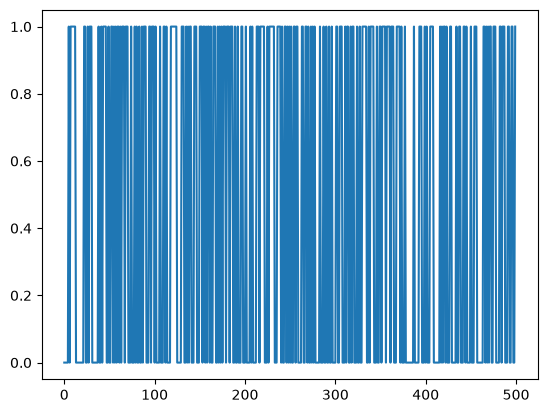

In [9]:
import matplotlib.pylab as plt
plt.plot(leaked_data[0:500])
plt.show()

Do you think we'll be able to get something useful out of this? Let's attack it to find out.

## AES Guesser

The attack is pretty simple. Let's just use our model of the device (we know what the encryption does after all, just not the secret key). 
And we'll feed in the observed data for each possible value of the key. 
And then we can observe how many (if any) of the keys result in the observation and simulation matching each other. If the observation and simulation match, this suggets our simulation is running in the same "setup" as the implementation we are attacking!

In [10]:
# compare two arrays a, b and return the number of cells which are equal
def num_same(a, b):
    
    if len(a) != len(b):
        raise ValueError("Arrays must be same length!")

    if max(a) != max(b):
        raise ValueError("Arrays max() should be the same!")
    
    #Count how many list items match up
    same = 0
    for i, _ in enumerate(a):
        if a[i] == b[i]:
            same += 1
    
    return same

In [11]:
#Simple test vectors - if you get the check-mark printed all OK.
assert(num_same([0,1,0,1,1,1,1,0], [0,1,0,1,1,1,1,0]) == 8)
assert(num_same([1,1,1,0,0,0,0,0], [0,1,0,1,1,1,1,0]) == 2)
assert(num_same([1, 0], [0, 1]) == 0)
print("✔️ OK to continue!")

✔️ OK to continue!


The next block is the most important. You'll need to "apply" the leakage function - that is for each known input byte, pass it through the `aes_internal(input_data, key_guess)` function. The value of `key_guess` is just integers in `[0x00, 0x01,...,0xFF]` - aka every possible value of the key byte. We'll compare the number of matching bits between our observed (leaked) data bit and the hypothetical data bit.

## Guessing Loop

In [12]:
for guess in range(0, 256):   
    
    # calculate the leakgee bit for every value in input_data 
    hypothetical_leakage = [aes_internal(guess, input_byte) & 0x01 for input_byte in input_data]
    
    # compare how many have the same leakage for an inout byte
    same_count = num_same(hypothetical_leakage, leaked_data)   
    
    #Print for debug
    #print("Guess {:02X}: {:4d} bits same".format(guess, same_count))

If your key guess is wrong, about half of the guesses should be wrong. 
Looking through the list, you'll see that most of the "bits same" numbers will be around 500. But scroll down to the correct key value (should be `0xEF` if you haven't changed it earlier). With any luck, that number should be fully correct - 1000 matching bits. This is only possible if the internal "secret key" byte matches the observed key.

with numpy.argsort we create an array with the index of the source_array sorted by value - lowest value first
with [::-1] we reverse the array - highes value first

In [13]:
import numpy as np
count_list = [2, 7, 24, 4, 5]
np.argsort(count_list)[::-1]

array([2, 1, 4, 3, 0])

Guessing loop with sort

In [14]:
import numpy as np

guess_list = [0] * 256

for guess in range(0, 256):   
    
    # calculate the leakgee bit for every value in input_data 
    hypothetical_leakage = [aes_internal(guess, input_byte) & 0x01 for input_byte in input_data]
    
    # compare how many have the same leakage for an inout byte
    same_count = num_same(hypothetical_leakage, leaked_data)   
    
    #Track the number of correct bits
    guess_list[guess] = same_count

#Use np.argsort to generate a list of indicies from low to high, then [::-1] to reverse the list to get high to low.
sorted_list = np.argsort(guess_list)[::-1]

#Print top 5 only
for guess in sorted_list[0:5]:
        print("Key Guess {:02X} = {:04d} matches".format(guess, guess_list[guess]))

Key Guess EF = 1000 matches
Key Guess B9 = 0583 matches
Key Guess 99 = 0579 matches
Key Guess 89 = 0576 matches
Key Guess 0C = 0573 matches


## Do the same with another bit

In [15]:
def get_bit(data, bit):
#    return (data >> bit) & 1
    if data & (1<<bit):
        return 1
    else:
        return 0

In [16]:
assert(get_bit(0xAA, 7) == 1)
assert(get_bit(0xAA, 0) == 0)
assert(get_bit(0x00, 7) == 0)
print("✔️ OK to continue!")

✔️ OK to continue!


In [17]:
def aes_leakage_guess(keyguess, inputdata, bit):
    return get_bit(aes_internal(keyguess, inputdata), bit)

In [18]:
assert(aes_leakage_guess(0xAB, 0x22, 4) == 0)
assert(aes_leakage_guess(0xAB, 0x22, 3) == 0)
assert(aes_leakage_guess(0xAB, 0x22, 2) == 1)
assert(aes_leakage_guess(0xAB, 0x22, 1) == 1)
assert(aes_leakage_guess(0xAB, 0x22, 0) == 1)
print("✔️ OK to continue!")

✔️ OK to continue!


If I do not know which bit I am observing I have to calculate all possible bits. The correct bit will have the most matches

In [19]:
for bit_guess in range(0, 8):
    guess_list = [0] * 256
    print("Checking bit {:d}".format(bit_guess))
    for guess in range(0, 256):

        #Get a hypothetical leakage for guessed bit (ensure returns 1/0 only)
        #Use bit_guess as the bit number, guess as the key guess, and data from input_data
        hypothetical_leakage = [aes_leakage_guess(guess, input_byte, bit_guess) & 0x01 for input_byte in input_data]

        #Use our function
        same_count = num_same(hypothetical_leakage, leaked_data)   

        #Track the number of correct bits
        guess_list[guess] = same_count

    sorted_list = np.argsort(guess_list)[::-1]

    #Print top 5 only
    for guess in sorted_list[0:2]:
            print("Key Guess {:02X} = {:04d} matches".format(guess, guess_list[guess]))

Checking bit 0
Key Guess EF = 1000 matches
Key Guess B9 = 0583 matches
Checking bit 1
Key Guess B5 = 0584 matches
Key Guess 29 = 0577 matches
Checking bit 2
Key Guess 3E = 0595 matches
Key Guess E1 = 0593 matches
Checking bit 3
Key Guess 31 = 0577 matches
Key Guess 25 = 0570 matches
Checking bit 4
Key Guess E7 = 0580 matches
Key Guess DF = 0580 matches
Checking bit 5
Key Guess C7 = 0588 matches
Key Guess BC = 0582 matches
Checking bit 6
Key Guess 0A = 0571 matches
Key Guess EE = 0570 matches
Checking bit 7
Key Guess FE = 0583 matches
Key Guess FB = 0582 matches


🥳🥳🥳🥳🥳🥳🥳🥳🥳🥳🥳🥳🥳
Congrats - you did it!!!!

This all assumed you get some way to observe the value of the bit - in our next act, we'll see how power analysis gives us the ability to observe a given bit.

## 4. Bonus: Adding Noise and Plotting Success Rates

In [20]:
import random

def aes_secret_chance(inputdata, chance_correct):
        secret_key = 0xEF
        correct = aes_internal(secret_key, inputdata)

        if random.randint(0, 100) <= chance_correct:
            return correct
        else:
            return 0

        
def num_same(a, b):
    
    if len(a) != len(b):
        raise ValueError("Arrays must be same length!")
    
    #Count how many list items match up
    same = 0
    for i, _ in enumerate(a):
        if a[i] == b[i]:
            same += 1
    
    return same
        
#This sets the percentage of correct observations
chances_to_try = range(20, 105, 5)
traces_needed = []
    
for chance_correct in chances_to_try:
    leaked_data = [(aes_secret_chance(a, chance_correct) & 0x01) for a in input_data]
        
    #Try for number of traces
    for traces in range(1, len(input_data), 1):
        
        guess_list = [0] * 256

        for guess in range(0, 256):
    
            #Get a hypothetical leakage list - use aes_internal(guess, input_byte) and mask off to only get value of lowest bit
            hypothetical_leakage = [aes_internal(guess, input_byte) & 0x01 for input_byte in input_data[0:traces]]

            #Use our function
            same_count = num_same(hypothetical_leakage, leaked_data[0:traces])

            #Track the number of correct bits
            guess_list[guess] = same_count

        #Use np.argsort to generate a list of indicies from low to high, then [::-1] to reverse the list to get high to low.
        sorted_list = np.argsort(guess_list)[::-1]
        
        if sorted_list[0] == 0xEF:
            print("Found key at %d %% correct data with %d encryptions"%(chance_correct, traces))
            traces_needed.append(traces)
            break
            
    if sorted_list[0] != 0xEF:
        raise ValueError("Failed to find answer for %d %% - need more traces"%(chance_correct))

Found key at 20 % correct data with 132 encryptions
Found key at 25 % correct data with 82 encryptions
Found key at 30 % correct data with 7 encryptions
Found key at 35 % correct data with 24 encryptions
Found key at 40 % correct data with 17 encryptions
Found key at 45 % correct data with 7 encryptions
Found key at 50 % correct data with 7 encryptions
Found key at 55 % correct data with 7 encryptions
Found key at 60 % correct data with 25 encryptions
Found key at 65 % correct data with 7 encryptions
Found key at 70 % correct data with 7 encryptions
Found key at 75 % correct data with 7 encryptions
Found key at 80 % correct data with 7 encryptions
Found key at 85 % correct data with 7 encryptions
Found key at 90 % correct data with 7 encryptions
Found key at 95 % correct data with 7 encryptions
Found key at 100 % correct data with 7 encryptions


Text(0, 0.5, 'Encryptions To Recover Key')

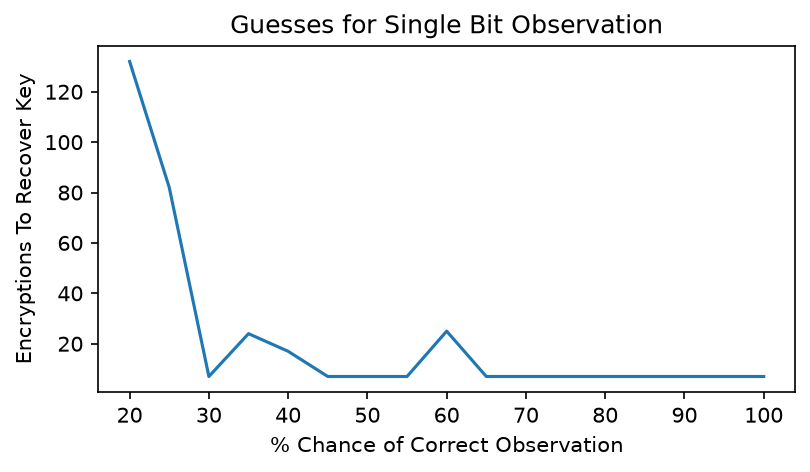

In [21]:
import matplotlib.pylab as plt

plt.figure(figsize=(6,3), dpi=150)
plt.plot(chances_to_try, traces_needed)
plt.title('Guesses for Single Bit Observation')
plt.xlabel('% Chance of Correct Observation')
plt.ylabel('Encryptions To Recover Key')

---
<small>NO-FUN DISCLAIMER: This material is Copyright (C) NewAE Technology Inc., 2015-2020. ChipWhisperer is a trademark of NewAE Technology Inc., claimed in all jurisdictions, and registered in at least the United States of America, European Union, and Peoples Republic of China.

Tutorials derived from our open-source work must be released under the associated open-source license, and notice of the source must be *clearly displayed*. Only original copyright holders may license or authorize other distribution - while NewAE Technology Inc. holds the copyright for many tutorials, the github repository includes community contributions which we cannot license under special terms and **must** be maintained as an open-source release. Please contact us for special permissions (where possible).

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE SOFTWARE.</small>